In [1]:
import numpy as np
import pandas as pd
from helper import process_fice
from pathlib import Path

In [2]:
mappings = {
    'DBPedia100k': ('/Users/lukas/Desktop/ablation-study-dbpedia', '/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/notebooks/fice_runs/dbpedia100k'),
    'WikiData': ('/Users/lukas/Desktop/fice-ablation-wikidata-gut', '/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/notebooks/fice_runs/wikidata'),
    'LUBM': ('/Users/lukas/Desktop/ablation-lubm', '/Users/lukas/Workspace/Uni/BachelorsThesis/FICE/notebooks/fice_runs/lubm'),
}

In [3]:
df = pd.DataFrame()
for dataset_name, (ablation_path, run_path) in mappings.items():
    for dtype in ['path', 'star']:
        print(f"Processing {dataset_name} with dtype {dtype}")
        
        ablation_df = process_fice(ablation_path, dataset_name.lower(), dtype)
        run_df = process_fice(run_path, dataset_name.lower(), dtype)
        ablation_df['dataset_name'] = dataset_name
        ablation_df['type'] = dtype
        ablation_df['method'] = 'ablation_study'
        run_df['type'] = dtype
        run_df['dataset_name'] = dataset_name

        df = pd.concat([df, ablation_df, run_df], ignore_index=True)

Processing DBPedia100k with dtype path
Selecting best epoch based on Loss
Using best epoch: 38
Selecting best epoch based on Loss
Using best epoch: 5
Processing DBPedia100k with dtype star
Selecting best epoch based on Loss
Using best epoch: 5
Selecting best epoch based on Loss
Using best epoch: 33
Processing WikiData with dtype path
Selecting best epoch based on Loss
Using best epoch: 12
Selecting best epoch based on Loss
Using best epoch: 34
Processing WikiData with dtype star
Selecting best epoch based on Loss
Using best epoch: 3
Selecting best epoch based on Loss
Using best epoch: 7
Processing LUBM with dtype path
Selecting best epoch based on Loss
Using best epoch: 1
Selecting best epoch based on Loss
Using best epoch: 61
Processing LUBM with dtype star
Selecting best epoch based on Loss
Using best epoch: 10
Selecting best epoch based on Loss
Using best epoch: 91


In [4]:
df.head()

,q_error,prediction,true_value,loss,method,dataset_name,type
0,4.002905,11888.629883,2970.000488,7.954195e+07,ablation_study,DBPedia100k,path
1,12.558868,62.794338,5.000000,3.340186e+03,ablation_study,DBPedia100k,path
2,3.873161,19.365807,5.000000,2.063764e+02,ablation_study,DBPedia100k,path
3,1.180951,1.180951,1.000000,3.274322e-02,ablation_study,DBPedia100k,path
4,1.258617,5.034468,4.000000,1.070124e+00,ablation_study,DBPedia100k,path


In [5]:
df_table = df.pivot_table(index=['dataset_name', 'type'], columns='method', values='q_error', aggfunc='median').reset_index()
df_table['percentage_change'] = ((df_table['ablation_study'] - df_table['fice']) / df_table['fice']) * 100

In [6]:
df_table

method,dataset_name,type,ablation_study,fice,percentage_change
0,DBPedia100k,path,2.730570,2.504694,9.018116
1,DBPedia100k,star,4.018188,3.574170,12.422982
2,LUBM,path,2.745651,1.053028,160.738583
3,LUBM,star,3.787836,1.071454,253.522790
4,WikiData,path,10.043748,7.191646,39.658541
5,WikiData,star,18.134068,6.861367,164.292356


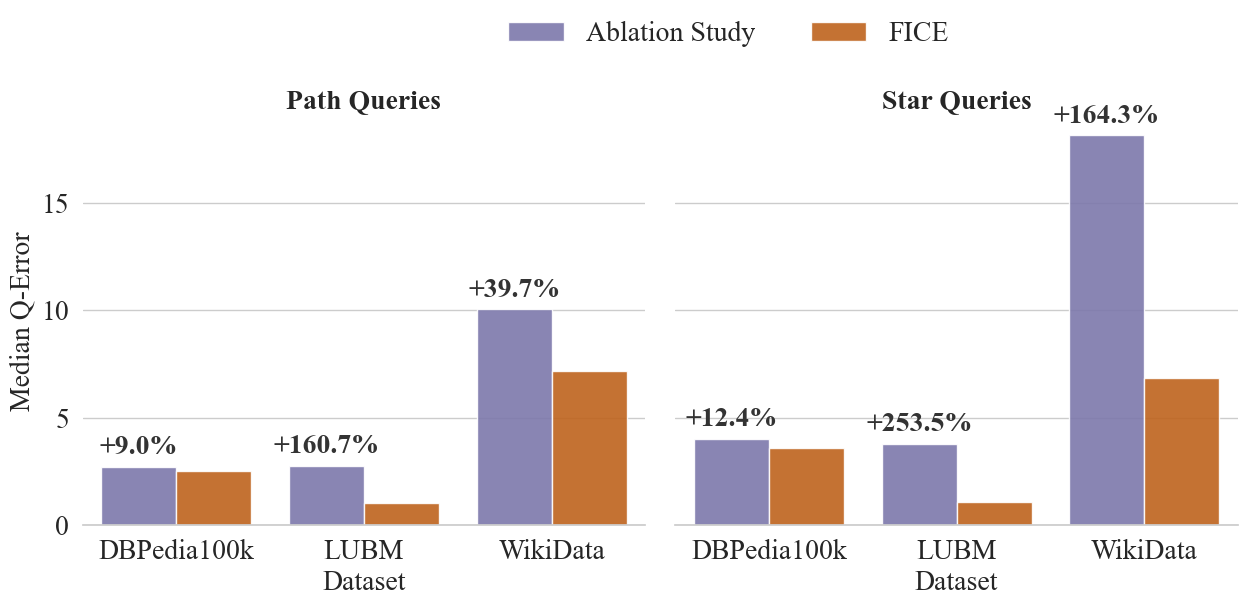

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

# 1. Setup Aesthetics (Serif & Larger Fonts)
# Increase font_scale from 1.15 -> 1.5 for larger overall text
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.5)
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'DejaVu Serif', 'serif'],
    'font.size': 20,
    'axes.titleweight': 'bold',
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 20,
})

# --- Data Preprocessing ---
# (Assuming df_table is already loaded in your environment)
df_table['type'] = df_table['type'].str.capitalize()

percent_map = {}
for _, row in df_table.iterrows():
    key = (row['dataset_name'].lower(), row['type'].lower())
    percent_map[key] = row['percentage_change']

df_melted = df_table.melt(
    id_vars=['dataset_name', 'type'], 
    value_vars=['ablation_study', 'fice'], 
    var_name='Model', 
    value_name='Score'
)

name_map = {
    'ablation_study': 'Ablation Study', 
    'fice': 'FICE',
    'path': 'Path', 
    'star': 'Star'
}
df_melted['Model'] = df_melted['Model'].replace(name_map)
df_melted['type'] = df_melted['type'].replace(name_map)

# --- Plotting ---
custom_palette = {'Ablation Study': '#7570b3', 'FICE': '#d95f02'}

# Increased height slightly to accommodate larger fonts
g = sns.catplot(
    data=df_melted, 
    kind="bar",
    x="dataset_name", 
    y="Score", 
    hue="Model",
    col="type", 
    palette=custom_palette, 
    alpha=0.9, 
    height=6,     # Increased height
    aspect=1.1,
    hue_order=['Ablation Study', 'FICE'],
    edgecolor="white",
    linewidth=1
)

g.set_axis_labels("Dataset", "Median Q-Error")
g.set_titles("{col_name} Queries")
g.despine(left=True)

# --- Annotation Logic ---

for ax in g.axes.flatten():
    query_type = ax.get_title().replace(' Queries', '').lower()
    datasets = [label.get_text() for label in ax.get_xticklabels()]
    
    if len(ax.containers) > 0:
        bars = ax.containers[0] 
        
        for bar, dataset in zip(bars, datasets):
            pct = percent_map.get((dataset.lower(), query_type))
            
            if pct is None or np.isnan(pct):
                continue
                
            label = f"{'+' if pct > 0 else ''}{pct:.1f}%"
            text_color = '#333333'
            
            height = bar.get_height()
            x_pos = bar.get_x() + bar.get_width() / 2
            
            ax.annotate(
                label,
                xy=(x_pos, height),
                xytext=(0, 5), # Increased offset slightly for larger font
                textcoords='offset points',
                ha='center', 
                va='bottom', 
                fontsize=20,   # Larger annotation font
                fontweight='bold',
                color=text_color,
                family='serif' # Ensure annotation is also serif
            )

# --- Legend and Final Adjustments ---
sns.move_legend(
    g, "upper center",
    bbox_to_anchor=(0.5, 1.05),
    ncol=2,
    title=None,
    frameon=False,
)

plt.subplots_adjust(top=0.85)
plt.savefig("ablation_study_serif.pdf", dpi=300, bbox_inches='tight')
plt.show()